Дані, розбиття, ознаки

In [1]:
import os, re, glob, time
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.preprocessing import QuantileTransformer

os.makedirs("results", exist_ok=True)
dev = torch.device("cuda")

def find(name):
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True)
    assert hits, f"не знайшов {name}: перевір Add Input"
    return hits[0]

tr = pd.read_csv(find("train_transaction.csv"))
idn = pd.read_csv(find("train_identity.csv"))
for c in tr.select_dtypes("float64").columns:
    tr[c] = tr[c].astype("float32")
df = tr.merge(idn, on="TransactionID", how="left")
df["has_identity"] = df["TransactionID"].isin(idn["TransactionID"])
df["day"] = (df["TransactionDT"] // 86400).astype(int)
df["week"] = df["day"] // 7
del tr

N = len(df)
TRAIN_W, VAL_W, TEST_W = (0, 17), (18, 21), (22, 26)
inw = lambda r: ((df.week >= r[0]) & (df.week <= r[1])).values
m_tr, m_va, m_te = inw(TRAIN_W), inw(VAL_W), inw(TEST_W)
assert (m_tr | m_va | m_te).all() and not (m_tr & m_va).any() and not (m_va & m_te).any()
assert (m_tr.sum(), m_va.sum(), m_te.sum()) == (431125, 77090, 82325)

ts, tid = df.TransactionDT.values, df.TransactionID.values
order = np.lexsort((tid, ts))
rank = np.empty(N, dtype=np.int64); rank[order] = np.arange(N)
y = df.isFraud.values
assert y.sum() == 20663
split_of = np.where(m_tr, 0, np.where(m_va, 1, 2))

X = df.drop(columns=["TransactionID", "isFraud", "TransactionDT", "day", "week"]).copy()
X["hour"] = (df.TransactionDT // 3600) % 24
X["weekday"] = (df.TransactionDT // 86400) % 7
X["has_identity"] = X["has_identity"].astype("int8")
for c in X.select_dtypes(include=["object", "category"]).columns:
    codes, _ = pd.factorize(X[c])
    X[c] = np.where(codes == -1, np.nan, codes).astype("float32")
spw = (y[m_tr] == 0).sum() / (y[m_tr] == 1).sum()

def metrics(y_true, p):
    k = int(y_true.sum()); o = np.argsort(-p)
    top1 = o[: max(1, int(0.01 * len(y_true)))]
    return {"pr_auc": average_precision_score(y_true, p),
            "roc_auc": roc_auc_score(y_true, p),
            "recall@k": y_true[o[:k]].sum() / k,
            "precision@1%": y_true[top1].mean(),
            "base_rate": y_true.mean()}
print("готово:", X.shape)

готово: (590540, 434)


Граф, таблиці сусідів, мітки з вікном 30 днів

In [2]:
def build_edges(cols, K, W_days):
    valid = df[cols].notna().all(axis=1).values
    idx = np.flatnonzero(valid); sub = df.loc[valid, cols]
    S, D = [], []
    for pos in sub.groupby(cols, sort=False).indices.values():
        if len(pos) < 2: continue
        rows = idx[pos]; rows = rows[np.argsort(rank[rows], kind="stable")]
        tt = ts[rows]; n = len(rows)
        lo = np.maximum(np.arange(n) - K, np.searchsorted(tt, tt - W_days * 86400, side="left"))
        cnt = np.arange(n) - lo; tot = int(cnt.sum())
        if tot == 0: continue
        dst_l = np.repeat(np.arange(n), cnt)
        start = np.repeat(np.cumsum(cnt) - cnt, cnt)
        src_l = np.arange(tot) - start + np.repeat(lo, cnt)
        S.append(rows[src_l].astype(np.int32)); D.append(rows[dst_l].astype(np.int32))
    return np.concatenate(S), np.concatenate(D)

REL = {"u3": (["card1", "addr1", "P_emaildomain"], 50, 30),
       "u2": (["card1", "addr1"], 50, 30),
       "c1": (["card1"], 20, 30)}
R_NAMES = list(REL); KMAX = {k: v[1] for k, v in REL.items()}
edges = {k: build_edges(*v) for k, v in REL.items()}
for k, (s, d) in edges.items():
    assert (rank[s] < rank[d]).all() and (s != d).all()
    assert (split_of[s[split_of[d] == 0]] == 0).all()
    print(k, f"ребер {len(s):,}")

NBR, DEG = [], []
for rn in R_NAMES:
    s, d = edges[rn]
    o = np.argsort(d, kind="stable"); ds, ss = d[o], s[o]
    cnt = np.bincount(d, minlength=N); start = np.cumsum(cnt) - cnt
    pos = np.arange(len(ds)) - start[ds]
    assert pos.max() < KMAX[rn]
    tab = np.full((N, KMAX[rn]), -1, dtype=np.int32); tab[ds, pos] = ss
    NBR.append(torch.from_numpy(tab).to(dev))
    DEG.append(torch.from_numpy(cnt.astype(np.int64)).to(dev))

# ---- мітки сусідів: затримка 7 днів, вікно 30 днів ----
KEYS = {"c1": ["card1"], "u2": ["card1", "addr1"], "u3": ["card1", "addr1", "P_emaildomain"]}
DL, W_LAB = 7, 30

def label_feats_win(cols, W_days, DLd):
    valid = df[cols].notna().all(axis=1).values; idx = np.flatnonzero(valid)
    nk = np.full(N, np.nan, "float32"); fk = np.full(N, np.nan, "float32")
    for pos in df.loc[valid, cols].groupby(cols, sort=False).indices.values():
        rows = idx[pos]; rows = rows[np.argsort(rank[rows], kind="stable")]
        tt, ff = ts[rows], y[rows]; cs = np.concatenate([[0], np.cumsum(ff)])
        a = np.searchsorted(tt, tt, side="left")
        hi = np.minimum(np.searchsorted(tt, tt - DLd * 86400, side="right"), a)
        lo = np.minimum(np.searchsorted(tt, tt - W_days * 86400, side="left"), hi)
        nk[rows] = hi - lo; fk[rows] = cs[hi] - cs[lo]
    return nk, fk

LFw = {}
for rel, cols in KEYS.items():
    LFw[f"{rel}_nk"], LFw[f"{rel}_fk"] = label_feats_win(cols, W_LAB, DL)
LFw = pd.DataFrame(LFw)
for rel in KEYS:
    LFw[f"{rel}_rate"] = (LFw[f"{rel}_fk"] / LFw[f"{rel}_nk"].where(LFw[f"{rel}_nk"] > 0)).astype("float32")

# перевірка «в лоб»: мітки лише від сусідів віком від 7 до 30 днів
rng = np.random.default_rng(2); bad = 0
for rel, cols in KEYS.items():
    cand = np.flatnonzero(df[cols].notna().all(axis=1).values)
    for i in rng.choice(cand, 60, replace=False):
        same = np.ones(N, bool)
        for c in cols: same &= (df[c].values == df[c].values[i])
        kn = same & (ts <= ts[i] - DL * 86400) & (ts >= ts[i] - W_LAB * 86400)
        if (int(kn.sum()) != int(LFw[f"{rel}_nk"].values[i]) or
                int(y[kn].sum()) != int(LFw[f"{rel}_fk"].values[i])): bad += 1
assert bad == 0
print("граф і мітки з вікном готові, розбіжностей 0")

u3 ребер 5,295,877
u2 ребер 12,260,904
c1 ребер 9,739,081
граф і мітки з вікном готові, розбіжностей 0


Ознаки для нейромережі

In [3]:
Xn = X.values.astype("float32")
grp = lambda p: [i for i, c in enumerate(X.columns) if re.fullmatch(p, c)]
nanf = np.stack([np.isnan(Xn[:, g]).mean(1) for g in
                 (grp(r"V\d+"), grp(r"D\d+"), grp(r"id_\d+"), grp(r"M\d+"))], 1).astype("float32")
qt = QuantileTransformer(n_quantiles=200, output_distribution="normal",
                         subsample=200_000, random_state=0).fit(Xn[m_tr])
Xt = np.hstack([np.nan_to_num(qt.transform(Xn), nan=0.0).clip(-5, 5).astype("float32"), nanf])

cols_ = []
for r in KEYS:
    g = lambda k, r=r: np.nan_to_num(LFw[f"{r}_{k}"].values)
    cols_ += [np.log1p(g("nk")), np.log1p(g("fk")), g("rate"), (g("nk") > 0).astype("float32")]
M = np.stack(cols_, 1).astype("float32")
M = (M - M[m_tr].mean(0)) / (M[m_tr].std(0) + 1e-6)
XG_labW = torch.from_numpy(np.hstack([Xt, M])).half().to(dev)
print("вхід нейромережі:", tuple(XG_labW.shape))

вхід нейромережі: (590540, 450)


Моделі, тест на витік, навчання

In [4]:
def sample(nodes, r, s, gen=None):
    deg = DEG[r][nodes]
    u = torch.rand(nodes.shape[0], s, device=dev, generator=gen)
    idx = (u * deg.unsqueeze(1)).long().clamp_(max=KMAX[R_NAMES[r]] - 1)
    nb = NBR[r][nodes.unsqueeze(1), idx].long()
    valid = (deg > 0).unsqueeze(1).expand(-1, s) & (nb >= 0)
    return nb.clamp(min=0), valid

def hops(tgt, s1, s2, gen=None):
    B, R = tgt.shape[0], len(R_NAMES)
    n1, v1 = zip(*[sample(tgt, r, s1, gen) for r in range(R)])
    N1, M1 = torch.stack(n1, 1), torch.stack(v1, 1)
    n2, v2 = zip(*[sample(N1.reshape(-1), r, s2, gen) for r in range(R)])
    N2 = torch.stack(n2, 1).view(B, R, s1, R, s2)
    M2 = torch.stack(v2, 1).view(B, R, s1, R, s2) & M1[:, :, :, None, None]
    return N1, M1, N2, M2

class RelSAGE2(nn.Module):
    def __init__(self, F_in, H=128, R=3, drop=0.2):
        super().__init__()
        self.R = R
        self.enc = nn.Sequential(nn.Linear(F_in, H), nn.ReLU(), nn.Dropout(drop))
        self.W1s, self.W2s = nn.Linear(H, H), nn.Linear(H, H)
        self.W1n = nn.ModuleList([nn.Linear(H, H, bias=False) for _ in range(R)])
        self.W2n = nn.ModuleList([nn.Linear(H, H, bias=False) for _ in range(R)])
        self.out = nn.Sequential(nn.Dropout(drop), nn.Linear(H, 1))

    @staticmethod
    def mmean(e, m, dim):
        m = m.unsqueeze(-1).to(e.dtype)
        return (e * m).sum(dim) / m.sum(dim).clamp(min=1)

    def forward(self, XG, tgt, s1, s2, gen=None):
        B, R = tgt.shape[0], self.R
        N1, M1, N2, M2 = hops(tgt, s1, s2, gen)
        enc = lambda ids: self.enc(XG[ids].float())
        e_t = enc(tgt)
        e1 = enc(N1.reshape(-1)).view(B, R, s1, -1)
        e2 = enc(N2.reshape(-1)).view(B, R, s1, R, s2, -1)
        a2 = self.mmean(e2, M2, 4)
        h1_u = F.relu(self.W1s(e1) + sum(self.W1n[j](a2[:, :, :, j]) for j in range(R)))
        a1 = self.mmean(e1, M1, 2)
        h1_t = F.relu(self.W1s(e_t) + sum(self.W1n[j](a1[:, j]) for j in range(R)))
        ah = self.mmean(h1_u, M1, 2)
        h2 = F.relu(self.W2s(h1_t) + sum(self.W2n[j](ah[:, j]) for j in range(R)))
        return self.out(h2).squeeze(-1)

class MLPNet(nn.Module):
    def __init__(self, F_in, H=128, drop=0.2):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(F_in, H), nn.ReLU(), nn.Dropout(drop),
                                 nn.Linear(H, H), nn.ReLU(), nn.Dropout(drop), nn.Linear(H, 1))
    def forward(self, XG, tgt, s1=None, s2=None, gen=None):
        return self.net(XG[tgt].float()).squeeze(-1)

# ---- тест на витік на реальних вибірках сусідів ----
sp_t = torch.as_tensor(split_of, device=dev); t_t = torch.as_tensor(ts, device=dev)
rg = np.random.default_rng(0)
for sp, cap in [(0, 0), (1, 1)]:
    ids = torch.as_tensor(rg.choice(np.flatnonzero(split_of == sp), 4000, replace=False), device=dev)
    N1, M1, N2, M2 = hops(ids, 10, 5)
    assert (sp_t[N1[M1]] <= cap).all() and (sp_t[N2[M2]] <= cap).all(), "сусіди з майбутньої частини"
    assert (t_t[N1] <= t_t[ids][:, None, None])[M1].all(), "сусід пізніший за вузол (крок 1)"
    assert (t_t[N2] <= t_t[N1][:, :, :, None, None])[M2].all(), "сусід пізніший за вузол (крок 2)"
print("тест на витік пройдено")

@torch.no_grad()
def predict_avg(model, XG, idx_np, s1, s2, seed, S=1, bs=2048):
    model.eval(); ids = torch.as_tensor(idx_np, device=dev); acc = 0.0
    for s in range(S):
        gen = torch.Generator(device=dev); gen.manual_seed(1234 + 100 * seed + s)
        acc = acc + torch.cat([torch.sigmoid(model(XG, ids[i:i + bs], s1, s2, gen)).float().cpu()
                               for i in range(0, len(ids), bs)]).numpy()
    return acc / S

def run_nn(make_model, XG, seed, s1=10, s2=5, epochs=15, patience=4, bs=1024,
           lr=1e-3, final_S=1, tag=""):
    torch.manual_seed(seed); np.random.seed(seed)
    model = make_model(XG.shape[1]).to(dev)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    posw = torch.tensor(float(spw), device=dev)
    tr_idx = torch.as_tensor(np.flatnonzero(m_tr), device=dev)
    yt = torch.as_tensor(y, device=dev).float()
    va_idx, te_idx = np.flatnonzero(m_va), np.flatnonzero(m_te)
    best, best_ep, bad, state, t_all = -1.0, 0, 0, None, time.time()
    for ep in range(1, epochs + 1):
        model.train(); t0 = time.time()
        perm = tr_idx[torch.randperm(len(tr_idx), device=dev)]
        for i in range(0, len(perm), bs):
            b = perm[i:i + bs]
            loss = F.binary_cross_entropy_with_logits(model(XG, b, s1, s2), yt[b], pos_weight=posw)
            opt.zero_grad(); loss.backward(); opt.step()
        v = average_precision_score(y[m_va], predict_avg(model, XG, va_idx, s1, s2, seed, S=1))
        print(f"{tag} seed {seed} епоха {ep}: val PR-AUC {v:.4f} | {time.time()-t0:.0f} с", flush=True)
        if v > best:
            best, best_ep, bad = v, ep, 0
            state = {k: t.detach().clone() for k, t in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(state)
    r = metrics(y[m_te], predict_avg(model, XG, te_idx, s1, s2, seed, S=final_S))
    r.update(seed=seed, best_epoch=best_ep, val_aucpr=best, secs=time.time() - t_all)
    return r

тест на витік пройдено


Запуск (seed 0)

In [5]:
res_w = []
for tag, mk_ in [("MLP B, вікно 30", MLPNet), ("GNN B, вікно 30", RelSAGE2)]:
    r = run_nn(mk_, XG_labW, 0, tag=tag); r["variant"] = tag; res_w.append(r)
    print(tag, {k: round(float(r[k]), 4) for k in ("pr_auc", "roc_auc", "recall@k", "precision@1%")}, flush=True)

out = pd.DataFrame(res_w)[["variant", "pr_auc", "roc_auc", "recall@k", "precision@1%",
                           "best_epoch", "val_aucpr", "secs", "seed"]]
out.to_csv("results/ieee_cis_nn_label_window30_seed0.csv", index=False)
out.round(4)

MLP B, вікно 30 seed 0 епоха 1: val PR-AUC 0.5149 | 1 с
MLP B, вікно 30 seed 0 епоха 2: val PR-AUC 0.5497 | 1 с
MLP B, вікно 30 seed 0 епоха 3: val PR-AUC 0.5604 | 1 с
MLP B, вікно 30 seed 0 епоха 4: val PR-AUC 0.5718 | 1 с
MLP B, вікно 30 seed 0 епоха 5: val PR-AUC 0.5657 | 1 с
MLP B, вікно 30 seed 0 епоха 6: val PR-AUC 0.5827 | 1 с
MLP B, вікно 30 seed 0 епоха 7: val PR-AUC 0.5641 | 1 с
MLP B, вікно 30 seed 0 епоха 8: val PR-AUC 0.5817 | 1 с
MLP B, вікно 30 seed 0 епоха 9: val PR-AUC 0.5854 | 1 с
MLP B, вікно 30 seed 0 епоха 10: val PR-AUC 0.5935 | 1 с
MLP B, вікно 30 seed 0 епоха 11: val PR-AUC 0.5831 | 1 с
MLP B, вікно 30 seed 0 епоха 12: val PR-AUC 0.5877 | 1 с
MLP B, вікно 30 seed 0 епоха 13: val PR-AUC 0.5936 | 1 с
MLP B, вікно 30 seed 0 епоха 14: val PR-AUC 0.5912 | 1 с
MLP B, вікно 30 seed 0 епоха 15: val PR-AUC 0.5827 | 1 с
MLP B, вікно 30 {'pr_auc': 0.5497, 'roc_auc': 0.9185, 'recall@k': 0.5345, 'precision@1%': 0.8566}
GNN B, вікно 30 seed 0 епоха 1: val PR-AUC 0.5305 | 28 с

,variant,pr_auc,roc_auc,recall@k,precision@1%,best_epoch,val_aucpr,secs,seed
0,"MLP B, вікно 30",0.5497,0.9185,0.5345,0.8566,13,0.5936,13.5729,0
1,"GNN B, вікно 30",0.5554,0.9207,0.5418,0.8663,4,0.5881,233.3818,0


П'ять seed у єдиному протоколі

/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [16:59:44] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


XGBoost без міток готово
XGBoost + мітки (W30) готово
MLP B, вікно 30 seed 1 епоха 1: val PR-AUC 0.5235 | 1 с
MLP B, вікно 30 seed 1 епоха 2: val PR-AUC 0.5548 | 1 с
MLP B, вікно 30 seed 1 епоха 3: val PR-AUC 0.5624 | 1 с
MLP B, вікно 30 seed 1 епоха 4: val PR-AUC 0.5649 | 1 с
MLP B, вікно 30 seed 1 епоха 5: val PR-AUC 0.5703 | 1 с
MLP B, вікно 30 seed 1 епоха 6: val PR-AUC 0.5795 | 1 с
MLP B, вікно 30 seed 1 епоха 7: val PR-AUC 0.5760 | 1 с
MLP B, вікно 30 seed 1 епоха 8: val PR-AUC 0.5722 | 1 с
MLP B, вікно 30 seed 1 епоха 9: val PR-AUC 0.5795 | 1 с
MLP B, вікно 30 seed 1 епоха 10: val PR-AUC 0.5849 | 1 с
MLP B, вікно 30 seed 1 епоха 11: val PR-AUC 0.5877 | 1 с
MLP B, вікно 30 seed 1 епоха 12: val PR-AUC 0.5775 | 1 с
MLP B, вікно 30 seed 1 епоха 13: val PR-AUC 0.5788 | 1 с
MLP B, вікно 30 seed 1 епоха 14: val PR-AUC 0.5884 | 1 с
MLP B, вікно 30 seed 1 епоха 15: val PR-AUC 0.6012 | 1 с
MLP B, вікно 30 1 0.5546
MLP B, вікно 30 seed 2 епоха 1: val PR-AUC 0.5042 | 1 с
MLP B, вікно 30 see

pr_auc        roc_auc        recall@k         \
                        mean    std    mean    std     mean    std   
variant                                                              
XGBoost без міток      0.505  0.003   0.886  0.005    0.487  0.006   
XGBoost + мітки (W30)  0.594  0.003   0.926  0.003    0.560  0.003   
MLP B, вікно 30        0.548  0.006   0.914  0.005    0.533  0.007   
GNN B, вікно 30        0.546  0.006   0.916  0.003    0.536  0.006   

                      precision@1%         
                              mean    std  
variant                                    
XGBoost без міток            0.876  0.007  
XGBoost + мітки (W30)        0.901  0.005  
MLP B, вікно 30              0.856  0.003  
GNN B, вікно 30              0.857  0.008

FileNotFoundError: [Errno 2] No such file or directory: 'results/figures/ieee_cis_final_models.png'

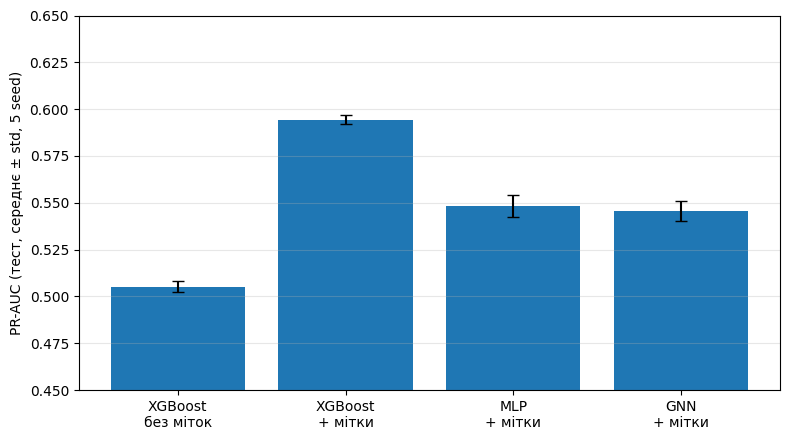

In [6]:
import xgboost as xgb
from xgboost import XGBClassifier
import matplotlib.pyplot as plt

major = int(xgb.__version__.split(".")[0])
DEV = dict(tree_method="hist", device="cuda") if major >= 2 else dict(tree_method="gpu_hist")

def run_xgb_X(Xf, seed):
    m = XGBClassifier(n_estimators=1000, learning_rate=0.1, max_depth=6,
                      subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw,
                      eval_metric="aucpr", early_stopping_rounds=50,
                      random_state=seed, **DEV)
    m.fit(Xf[m_tr], y[m_tr], eval_set=[(Xf[m_va], y[m_va])], verbose=False)
    r = metrics(y[m_te], m.predict_proba(Xf[m_te])[:, 1])
    r.update(seed=seed, best_epoch=m.best_iteration, val_aucpr=m.best_score)
    return r

rows = []
Xlab = pd.concat([X, LFw], axis=1)
for name, Xf in [("XGBoost без міток", X), ("XGBoost + мітки (W30)", Xlab)]:
    for sd in range(5):
        r = run_xgb_X(Xf, sd); r["variant"] = name; rows.append(r)
    print(name, "готово", flush=True)

try:
    seed0 = pd.DataFrame(res_w)
except NameError:
    seed0 = pd.read_csv("results/ieee_cis_nn_label_window30_seed0.csv")
for _, r in seed0.iterrows():
    rows.append(r.to_dict())

for tag, mk_ in [("MLP B, вікно 30", MLPNet), ("GNN B, вікно 30", RelSAGE2)]:
    for sd in range(1, 5):
        r = run_nn(mk_, XG_labW, sd, tag=tag); r["variant"] = tag; rows.append(r)
        print(tag, sd, round(float(r["pr_auc"]), 4), flush=True)

final = pd.DataFrame(rows)
final.to_csv("results/ieee_cis_final_models_5seeds.csv", index=False)
order = ["XGBoost без міток", "XGBoost + мітки (W30)", "MLP B, вікно 30", "GNN B, вікно 30"]
tab = final.groupby("variant")[["pr_auc", "roc_auc", "recall@k", "precision@1%"]].agg(["mean", "std"]).reindex(order).round(3)
display(tab)

s = final.groupby("variant")["pr_auc"].agg(["mean", "std"]).reindex(order)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(range(4), s["mean"], yerr=s["std"], capsize=4)
ax.set_xticks(range(4)); ax.set_xticklabels(["XGBoost\nбез міток", "XGBoost\n+ мітки", "MLP\n+ мітки", "GNN\n+ мітки"])
ax.set_ylabel("PR-AUC (тест, середнє ± std, 5 seed)"); ax.set_ylim(0.45, 0.65); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig("results/figures/ieee_cis_final_models.png", dpi=200); plt.show()